In [1]:
# Import the instructor-provided data generator.
from latedeliveries.data import make_orders

# Generate the original delivery dataset.
orders = make_orders()

# Calculate the number and percentage of late deliveries.
total_orders = len(orders)
late_orders = orders["late"].sum()
late_percentage = orders["late"].mean() * 100

# Display the dataset summary.
print(f"Total orders: {total_orders}")
print(f"Late orders: {late_orders}")
print(f"Late-delivery rate: {late_percentage:.2f}%")

Total orders: 3000
Late orders: 468
Late-delivery rate: 15.60%


In [2]:
# Import pandas to display the saved model comparison results.
from pathlib import Path

import pandas as pd

# Locate the project folder, whether Jupyter starts in the
# project root or inside the notebooks folder.
project_root = Path.cwd()
if not (project_root / "reports" / "cv_results.csv").exists():
    project_root = project_root.parent

# Load the five-fold cross-validation results already generated.
results = pd.read_csv(project_root / "reports" / "cv_results.csv")

# Display the mean and standard deviation of all five metrics.
print("Five-Fold Cross-Validation Model Comparison")
display(results.round(3))

Five-Fold Cross-Validation Model Comparison


,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,dummy,0.844,0.001,0.000,0.000,0.000,0.000,0.000,0.000,0.500,0.000
1,logistic_regression,0.855,0.014,0.607,0.162,0.199,0.058,0.298,0.083,0.769,0.028
2,balanced_logistic_regression,0.730,0.024,0.322,0.031,0.655,0.054,0.432,0.038,0.768,0.028
3,decision_tree,0.752,0.019,0.252,0.045,0.299,0.061,0.273,0.048,0.567,0.032
4,random_forest,0.834,0.013,0.447,0.069,0.245,0.058,0.313,0.061,0.699,0.023


Matplotlib is building the font cache; this may take a moment.


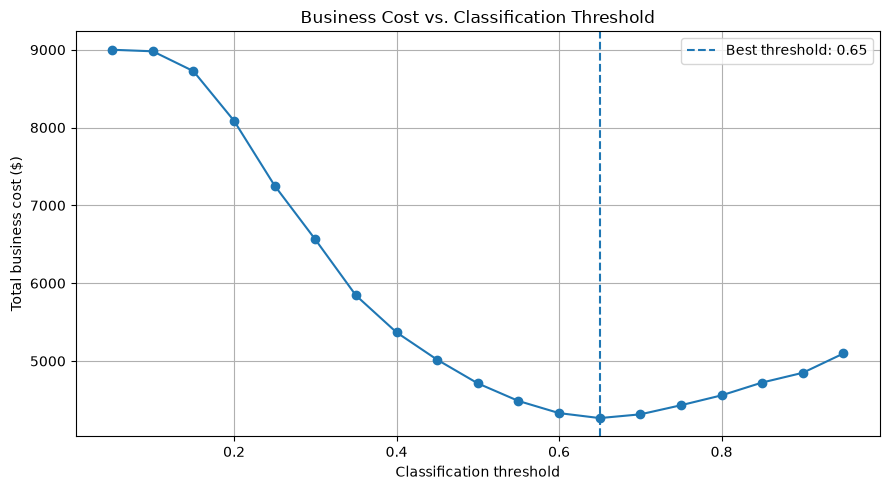

Best threshold: 0.65
Lowest training CV cost: $4267


In [3]:
# Import the tools needed to calculate and plot threshold costs.
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from latedeliveries.evaluation import choose_threshold, order_cost
from latedeliveries.models import get_candidate_models
from latedeliveries.pipeline import RANDOM_STATE, build_pipeline, split_orders

# Use training data only. The reserved test set is not evaluated here.
X_train, _, y_train, _ = split_orders(make_orders())

# Recreate the chosen model with its best hyperparameters.
model = get_candidate_models()["balanced_logistic_regression"]
model.set_params(C=0.1, fit_intercept=True)
pipeline = build_pipeline(model)

# Generate out-of-fold probabilities using five-fold cross-validation.
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

probabilities = cross_val_predict(
    pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
)[:, 1]

# Calculate business costs for all 19 required thresholds.
thresholds = [round(i * 0.05, 2) for i in range(1, 20)]
costs = [order_cost(y_train, probabilities >= threshold) for threshold in thresholds]

# Identify the lowest-cost threshold.
best_threshold, best_cost = choose_threshold(y_train, probabilities)

# Create the required cost-versus-threshold chart.
plt.figure(figsize=(9, 5))
plt.plot(thresholds, costs, marker="o")
plt.axvline(
    best_threshold,
    linestyle="--",
    label=f"Best threshold: {best_threshold:.2f}",
)

plt.xlabel("Classification threshold")
plt.ylabel("Total business cost ($)")
plt.title("Business Cost vs. Classification Threshold")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"Best threshold: {best_threshold:.2f}")
print(f"Lowest training CV cost: ${best_cost}")

In [4]:
# Read the final test results saved by the training program.
import json

with (project_root / "reports" / "metrics.json").open(encoding="utf-8") as file:
    metrics = json.load(file)

# Display the saved test-set confusion matrix.
confusion = pd.DataFrame(
    metrics["confusion_matrix"],
    index=["Actually on time", "Actually late"],
    columns=["Predicted on time", "Predicted late"],
)

print("Final Test-Set Confusion Matrix")
display(confusion)

# Display the final classification metrics.
print("\nFinal Test-Set Metrics")
print(f"Precision: {metrics['precision']:.4f}")
print(f"Recall: {metrics['recall']:.4f}")
print(f"F1-score: {metrics['f1']:.4f}")
print(f"ROC-AUC: {metrics['roc_auc']:.4f}")

# Compare the costs of the three business policies.
costs = metrics["costs"]

print("\nBusiness Policy Costs (750 Test Orders)")
print(f"Flag nobody: ${costs['flag_nobody']}")
print(f"Flag everybody: ${costs['flag_everybody']}")
print(f"Our model: ${costs['model']}")
print(f"Savings: ${costs['flag_nobody'] - costs['model']}")

Final Test-Set Confusion Matrix


,Predicted on time,Predicted late
Actually on time,568,65
Actually late,64,53



Final Test-Set Metrics
Precision: 0.4492
Recall: 0.4530
F1-score: 0.4511
ROC-AUC: 0.7636

Business Policy Costs (750 Test Orders)
Flag nobody: $1755
Flag everybody: $3000
Our model: $1432
Savings: $323


### Final Recommendation

I recommend using the Balanced Logistic Regression model in a limited pilot before considering full deployment. On the 750-order test set, the model reduced estimated business costs from $1,755 to $1,432, saving $323 (18.4%).

The classification threshold of 0.65 was selected using out-of-fold predictions on training data. It minimized the company's estimated costs based on $4 per flagged order and $15 per missed late delivery.

I excluded the order ID because it is only an identifier. Vehicle type and courier experience were excluded because courier assignment information may not be available when an order is placed. Actual preparation time was excluded because it is not yet known, and customer rating was excluded because it is collected after delivery.

One important limitation is that the dataset is simulated rather than based on real delivery operations. Additionally, the model missed 64 late deliveries in the test set. Further validation using real delivery data would be necessary before deployment.